### Employee Turnover Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder

In [8]:
csv = pd.read_csv(r'B:\Project-git\employee-ml-analysis\HR_comma_sep.csv')
df = pd.DataFrame(csv)

data quality checks by checking for missing values, if any.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [35]:
df.isna().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

In [36]:
df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [9]:
df.drop_duplicates(inplace=True)

In [5]:
df["salary"].value_counts()

salary
low       5740
medium    5261
high       990
Name: count, dtype: int64

In [6]:
df["sales"].value_counts()

sales
sales          3239
technical      2244
support        1821
IT              976
RandD           694
product_mng     686
marketing       673
accounting      621
hr              601
management      436
Name: count, dtype: int64

### what factors contributed most to employee turnover

LabelEncoder implemented on [salary] & [sales]

In [ ]:
'''
0 - high
1 - low
2 - medium
'''
df["salary_encoded"] = LabelEncoder().fit_transform(df["salary"])
# df['sales_encoded'] = LabelEncoder().fit_transform(df['sales'])
df["sales_frequency"] = df.groupby('sales')['sales'].transform('count')

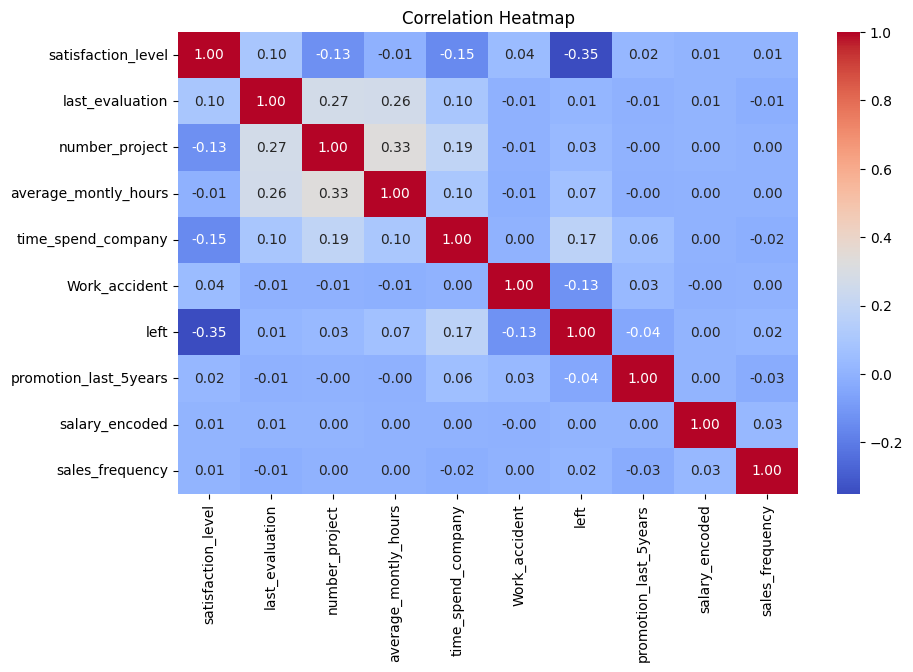

In [21]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.drop(columns=['sales','salary']).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [12]:
df["left"].value_counts()

left
0    10000
1     1991
Name: count, dtype: int64

Distribution plot

■	Employee Satisfaction [satisfaction_level]

<Figure size 1000x600 with 0 Axes>

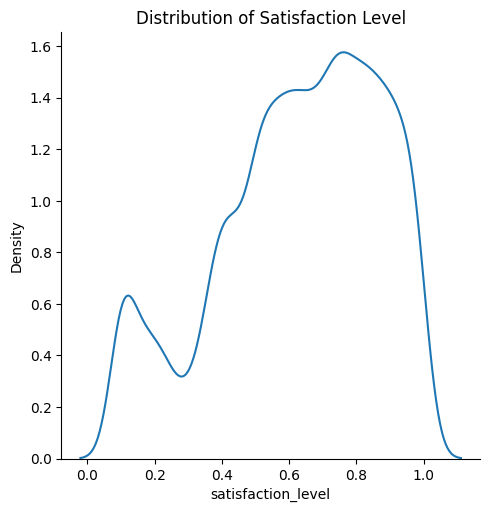

In [25]:
plt.figure(figsize=(10, 6))
sns.displot(data=df, x="satisfaction_level", kind="kde")
plt.title('Distribution of Satisfaction Level')
plt.show()

■	Employee Evaluation [last_evaluation]

<Figure size 1000x600 with 0 Axes>

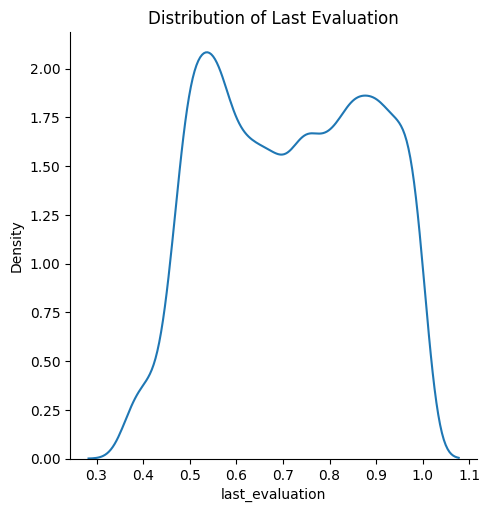

In [26]:
plt.figure(figsize=(10, 6))
sns.displot(data=df, x="last_evaluation", kind="kde")
plt.title('Distribution of Last Evaluation')
plt.show()

■	Employee Average Monthly Hours [average_montly_hours]

<Figure size 1000x600 with 0 Axes>

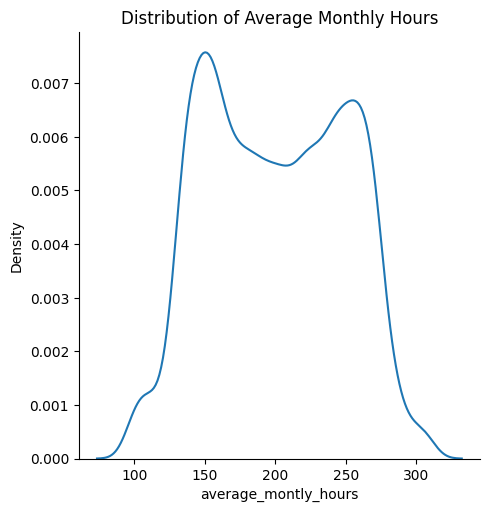

In [27]:
plt.figure(figsize=(10, 6))
sns.displot(data=df, x="average_montly_hours", kind="kde")
plt.title('Distribution of Average Monthly Hours')
plt.show()